# 04 Extreme Frequency Plots

In [28]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting, regions, plot_ext_freq_combined
from cdrmip_extremes.load_processed import load_extremes, load_land_ocean_masks
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [30]:
ext_data = load_extremes(
    PROC_DIR, 'CDRMIP',
    outputs=['exceedances_median_multimodel', 'branch_differences_median_multimodel','agreement'],
    model_order=CDR_MODELS,
)

  sort_models: no order defined for ['multi_model_median'], appending at end
  sort_models: no order defined for ['multi_model_median'], appending at end


In [31]:
exceedances = ext_data['exceedances_median_multimodel']
differences = ext_data['branch_differences_median_multimodel']
agreement = ext_data['agreement']

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/main/figure2_v2.jpg


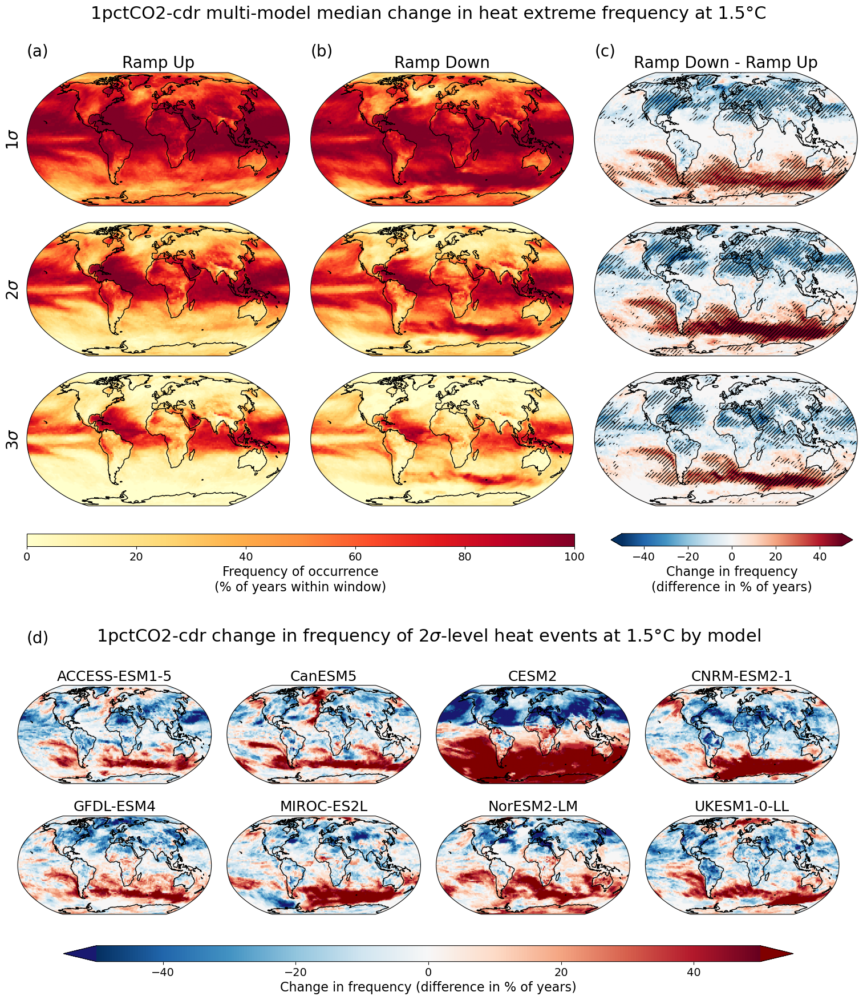

In [32]:
fig = plotting.plot_ext_freq_with_model_diffs(
    exceedances, differences, agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='heat',
    gwl=1.5, period='gwl', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in heat extreme frequency at 1.5°C',
    fig_dir=FIG_DIR, folder='main', file_name='figure2_v2.jpg',
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/main/figure3_v2.jpg


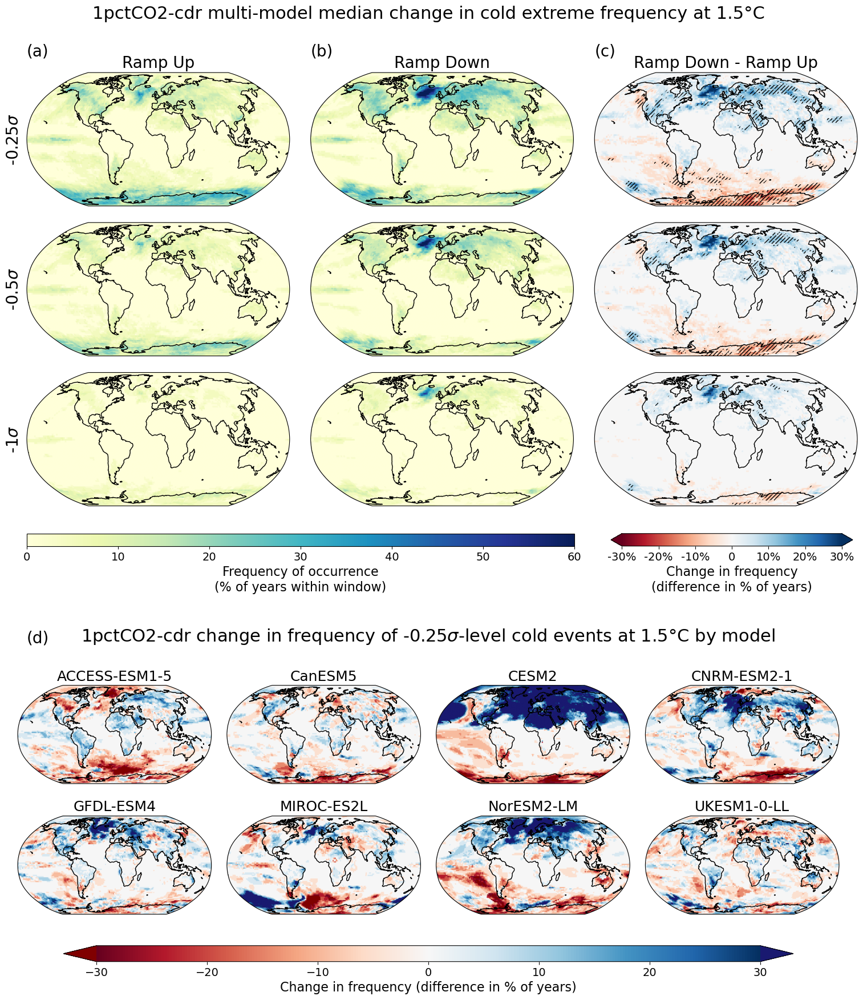

In [33]:
fig = plotting.plot_ext_freq_with_model_diffs(
    exceedances, differences, agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='cold',
    gwl=1.5, period='gwl', model_name='Multi-Model Median',
    diff_threshold='sigma1',          
    diff_vmin=-30, diff_vmax=30,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in cold extreme frequency at 1.5°C',
    fig_dir=FIG_DIR, folder='main', file_name='figure3_v2.jpg',
)

## Plot differences for each model

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S14.jpg


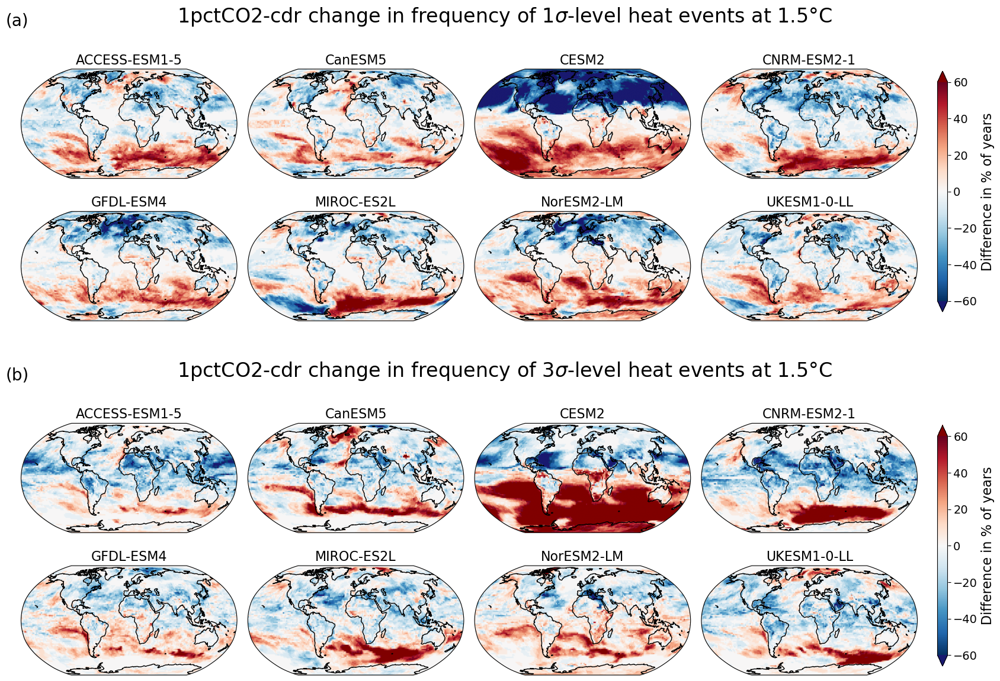

In [8]:
fig = plotting.plot_ext_freq_diff_stacked(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=1.5,
    panels=[
        {'threshold': 'sigma1', 'label': '(a)', 'title': '1$\\sigma$'},
        {'threshold': 'sigma3', 'label': '(b)', 'title': '3$\\sigma$'},
    ],
    vmin=-60, vmax=60,
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S14.jpg',
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S15.jpg


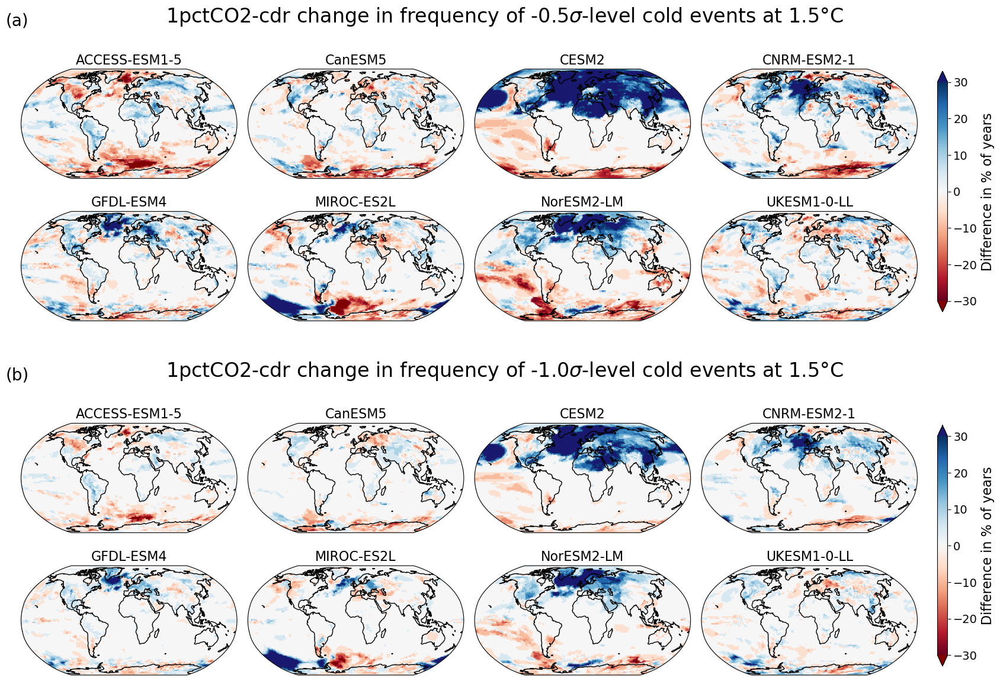

In [9]:
fig = plotting.plot_ext_freq_diff_stacked(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=1.5,
    panels=[
        {'threshold': 'sigma2', 'label': '(a)', 'title': '-0.5$\\sigma$'},
        {'threshold': 'sigma3', 'label': '(b)', 'title': '-1.0$\\sigma$'},
    ],
    vmin=-30, vmax=30,
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S15.jpg',
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S14a.jpg


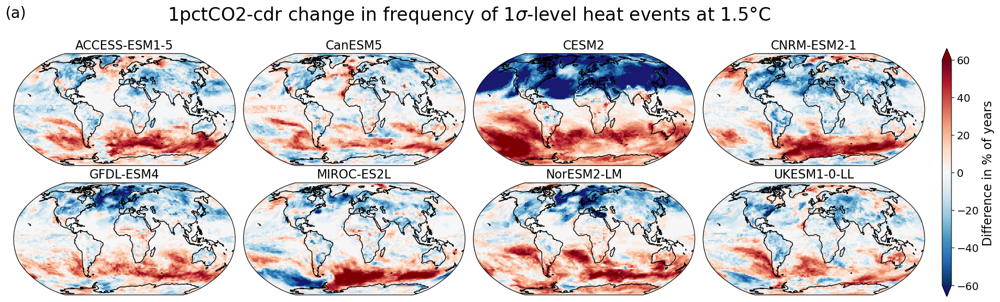

In [7]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=1.5,
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='1$\sigma$',
    vmin=-60,
    vmax=60,
    # period='gwl',
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S14a.jpg',
    
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/main/figure3.jpg


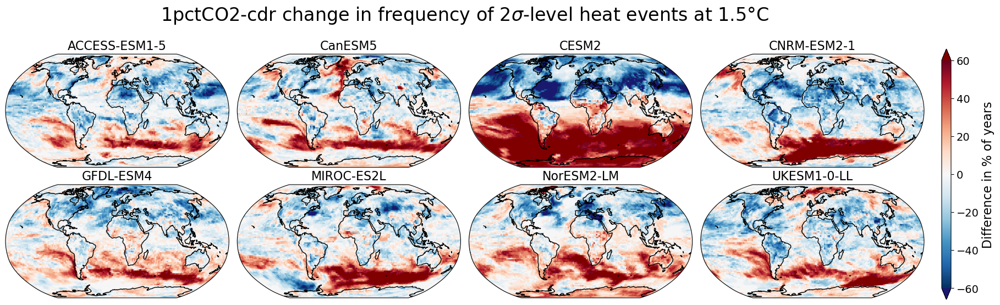

In [8]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=1.5,
    threshold='sigma2',
    levels=None,
    label=None,
    title='2$\sigma$',
    vmin=-60,
    vmax=60,
    fig_dir=FIG_DIR,
    folder='main',
    file_name='figure3.jpg'
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S14b.jpg


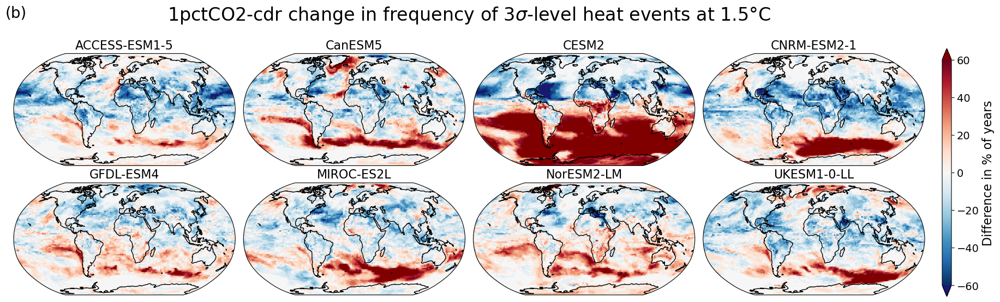

In [9]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=1.5,
    threshold='sigma3',
    levels=None,
    label='(b)',
    title='3$\sigma$',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S14b.jpg'
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/main/figure5.jpg


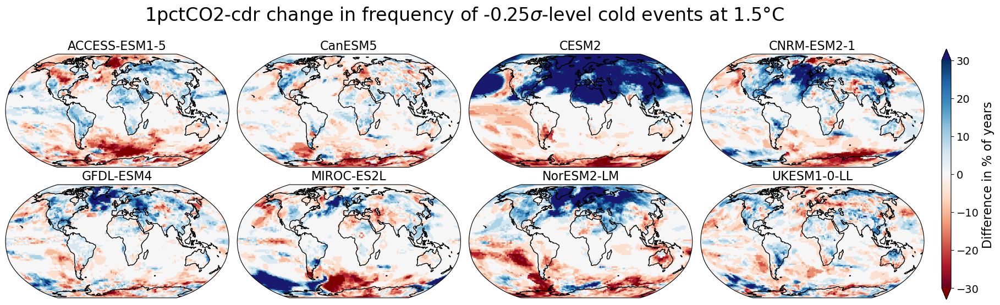

In [10]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=1.5,
    threshold='sigma1',
    levels=None,
    label=None,
    title='-0.25$\sigma$',
    vmin=-30,
    vmax=30,
    fig_dir=FIG_DIR,
    folder='main',
    file_name='figure5.jpg'
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S15a.jpg


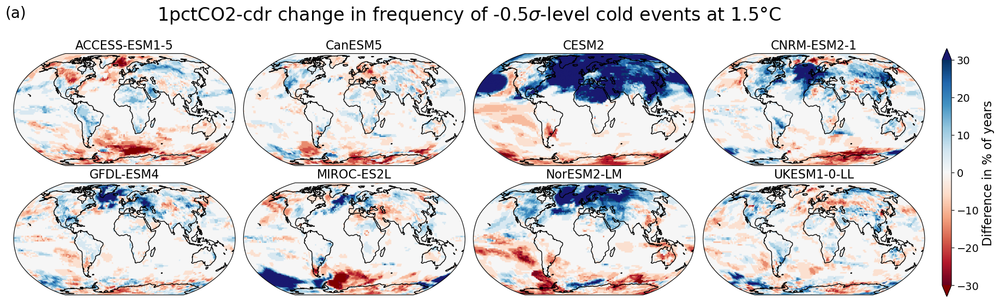

In [11]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=1.5,
    threshold='sigma2',
    levels=None,
    label='(a)',
    title='-0.5$\sigma$',
    vmin=-30,
    vmax=30,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S15a.jpg'
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S15b.jpg


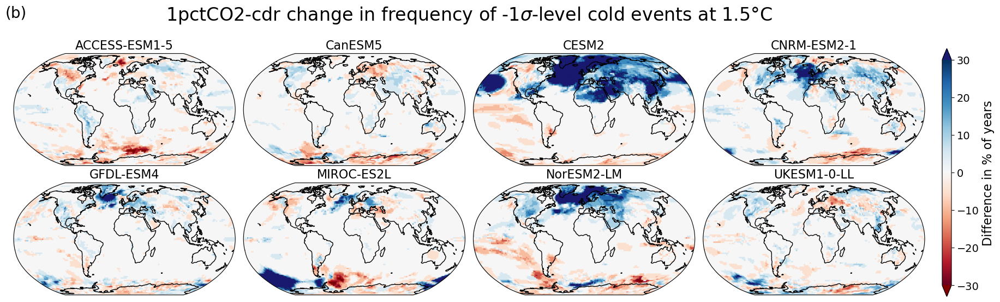

In [12]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=1.5,
    threshold='sigma3',
    levels=None,
    label='(b)',
    title='-1$\sigma$',
    vmin=-30,
    vmax=30,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S15b.jpg'
)

## Statistics

In [7]:
land_mask, ocean_mask = load_land_ocean_masks()

Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'source_id': 'ACCESS-ESM1-5', 'member_id': 'r1i1p1f1', 'table_id': 'fx', 'variable_id': ['sftlf']}
Loading ACCESS-ESM1-5 / r1i1p1f1
Building regridder for grid (145,) x (192,)


In [8]:
zonal_subsets_exc = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in exceedances.items():
        ds = exceedances[model]['1pctCO2-cdr'][ext_type].sel(gwl=1.5)
        zonal_subsets_exc[ext_type][model] = {
            'land': regions.get_zonal_subsets(ds,mask=land_mask),
            'ocean': regions.get_zonal_subsets(ds,mask=ocean_mask),
            'all': regions.get_zonal_subsets(ds,mask=None)
        }

In [9]:
zonal_subsets_diff = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in differences.items():
        ds = differences[model]['1pctCO2-cdr'][ext_type].sel(gwl=1.5)
        zonal_subsets_diff[ext_type][model] = {
            'land': regions.get_zonal_subsets(ds,mask=land_mask),
            'ocean': regions.get_zonal_subsets(ds,mask=ocean_mask),
            'all': regions.get_zonal_subsets(ds,mask=None)
        }

In [10]:
zonal_avgs_diff = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in differences.items():
        ds = differences[model]['1pctCO2-cdr'][ext_type].sel(gwl=1.5)
        zonal_avgs_diff[ext_type][model] = {
            'land': regions.get_zonal_averages(ds,mask=land_mask),
            'ocean': regions.get_zonal_averages(ds,mask=ocean_mask),
            'all': regions.get_zonal_averages(ds,mask=None)
        }

In [26]:
tropical_ocean = zonal_subsets_diff['heat']['multi_model_median']['ocean']['Tropics']
pct = regions.area_fraction_above(tropical_ocean)
print(pct.sigma2.values)

30.428544272719776


In [40]:
tropical_ocean = zonal_subsets_diff['heat']['multi_model_median']['ocean']['Tropics']
pct = regions.area_fraction_above(tropical_ocean,threshold=0)
print(pct.sigma1.values)
print(pct.sigma2.values)
print(pct.sigma3.values)

26.28153626157147
30.428544272719776
26.433017250571535


In [32]:
tropical_ocean = zonal_subsets_exc['heat']['multi_model_median']['ocean']['Tropics'].sel(branch='ramp_up')
pct = regions.area_fraction_above(tropical_ocean,threshold=50)
print(pct.sigma1.values)
print(pct.sigma2.values)
print(pct.sigma3.values)

99.67497336689952
80.33396398940138
51.48333935805523


In [31]:
tropical_ocean = zonal_subsets_exc['heat']['multi_model_median']['land']['Tropics'].sel(branch='ramp_up')
pct = regions.area_fraction_above(tropical_ocean,threshold=50)
print(pct.sigma1.values)
print(pct.sigma2.values)
print(pct.sigma3.values)

97.63705846409152
67.96465444433537
18.29439073785302


In [34]:
rows = []
ext_type='heat'
for surface in ['land', 'ocean']:
    zones = zonal_subsets_exc[ext_type]['multi_model_median'][surface]
    for zone, subset in zones.items():
        pct = regions.area_fraction_above(subset.sel(branch='ramp_up'), threshold=50)
        rows.append({
            'surface': surface,
            'zone': zone,
            'sigma1': float(pct.sigma1),
            'sigma2': float(pct.sigma2),
            'sigma3': float(pct.sigma3),
        })

df = pd.DataFrame(rows)
print(df.round(1).to_string(index=False))

surface                zone  sigma1  sigma2  sigma3
   land Southern Hemisphere    79.5    32.6     9.2
   land Northern Hemisphere    97.9    45.8     8.1
   land           Antarctic    56.3     0.0     0.0
   land     SH Extratropics    55.8     3.2     0.0
   land             Tropics    97.6    68.0    18.3
   land     NH Extratropics    99.3    36.5     1.8
   land              Arctic    90.9     3.2     0.0
  ocean Southern Hemisphere    80.7    32.0    15.4
  ocean Northern Hemisphere    95.0    75.6    44.9
  ocean           Antarctic    17.4     0.0     0.0
  ocean     SH Extratropics    74.2     0.2     0.0
  ocean             Tropics    99.7    80.3    51.5
  ocean     NH Extratropics    95.9    61.2     7.1
  ocean              Arctic    64.6     9.1     0.0


In [41]:
rows = []
ext_type='heat'
for surface in ['land', 'ocean']:
    zones = zonal_subsets_diff[ext_type]['multi_model_median'][surface]
    for zone, subset in zones.items():
        pct = regions.area_fraction_above(subset, threshold=0)
        rows.append({
            'surface': surface,
            'zone': zone,
            'sigma1': float(pct.sigma1),
            'sigma2': float(pct.sigma2),
            'sigma3': float(pct.sigma3),
        })

df = pd.DataFrame(rows)
print(df.round(1).to_string(index=False))

surface                zone  sigma1  sigma2  sigma3
   land Southern Hemisphere    45.7    46.2    30.0
   land Northern Hemisphere     6.5     5.1     3.6
   land           Antarctic    82.9    82.2    60.6
   land     SH Extratropics    70.6    64.4    43.5
   land             Tropics    19.6    18.0     9.9
   land     NH Extratropics     0.4     0.6     0.7
   land              Arctic     1.5     2.8     2.5
  ocean Southern Hemisphere    70.0    71.9    62.5
  ocean Northern Hemisphere     6.4     9.4     7.5
  ocean           Antarctic    67.7    66.6    35.2
  ocean     SH Extratropics    96.6    94.7    85.7
  ocean             Tropics    26.3    30.4    26.4
  ocean     NH Extratropics     9.8    15.6    15.1
  ocean              Arctic     8.6     7.4     5.7


In [14]:
rows = []
ext_type='cold'
for surface in ['land', 'ocean']:
    zones = zonal_subsets_diff[ext_type]['multi_model_median'][surface]
    for zone, subset in zones.items():
        pct = regions.area_fraction_above(subset, threshold=0)
        rows.append({
            'surface': surface,
            'zone': zone,
            'sigma1': float(pct.sigma1),
            'sigma2': float(pct.sigma2),
            'sigma3': float(pct.sigma3),
        })

df = pd.DataFrame(rows)
print(df.round(1).to_string(index=False))

surface                zone  sigma1  sigma2  sigma3
   land Southern Hemisphere    60.1    63.8    78.1
   land Northern Hemisphere    95.0    96.6    99.0
   land           Antarctic     7.6    11.0    39.8
   land     SH Extratropics    43.0    54.6    76.5
   land             Tropics    92.7    94.7    98.5
   land     NH Extratropics    95.6    96.3    99.0
   land              Arctic    92.0    96.3    98.0
  ocean Southern Hemisphere    64.6    77.7    94.5
  ocean Northern Hemisphere    91.9    95.6    99.4
  ocean           Antarctic    34.7    42.9    70.7
  ocean     SH Extratropics    51.1    71.0    95.2
  ocean             Tropics    88.9    94.0    99.2
  ocean     NH Extratropics    83.8    91.1    98.5
  ocean              Arctic    94.4    97.8   100.0


In [15]:
rows = []
ext_type='cold'
for surface in ['land', 'ocean']:
    zones = zonal_subsets_diff[ext_type]['multi_model_median'][surface]
    for zone, subset in zones.items():
        pct = regions.area_fraction_below(subset, threshold=0)
        rows.append({
            'surface': surface,
            'zone': zone,
            'sigma1': float(pct.sigma1),
            'sigma2': float(pct.sigma2),
            'sigma3': float(pct.sigma3),
        })

df = pd.DataFrame(rows)
print(df.round(1).to_string(index=False))

surface                zone  sigma1  sigma2  sigma3
   land Southern Hemisphere    40.1    36.5    21.9
   land Northern Hemisphere     5.2     3.5     1.1
   land           Antarctic    92.8    89.7    60.2
   land     SH Extratropics    57.6    46.2    23.5
   land             Tropics     7.4     5.3     1.5
   land     NH Extratropics     4.7     3.9     1.2
   land              Arctic     8.2     4.0     2.0
  ocean Southern Hemisphere    35.5    22.3     5.6
  ocean Northern Hemisphere     8.2     4.4     0.6
  ocean           Antarctic    66.2    57.6    29.5
  ocean     SH Extratropics    48.9    29.0     4.8
  ocean             Tropics    11.1     6.0     0.8
  ocean     NH Extratropics    16.6     9.0     1.5
  ocean              Arctic     5.8     2.2     0.0


In [39]:
ds = exceedances['multi_model_median']['1pctCO2-cdr']['heat'].sel(branch='ramp_up',gwl=1.5)
pct = regions.area_fraction_above(ds, threshold=50)
print(pct.sigma1.values, pct.sigma2.values, pct.sigma3.values)

88.28879818896542 48.04973866216826 22.41744358321593


In [12]:
ds = exceedances['multi_model_median']['1pctCO2-cdr']['cold'].sel(branch='ramp_up',gwl=1.5)
pct = regions.area_fraction_above(ds, threshold=4.5)
print(pct.sigma1.values, pct.sigma2.values, pct.sigma3.values)

45.05215657568759 30.421107278132283 10.349104216997038


In [13]:
ds = exceedances['multi_model_median']['1pctCO2-cdr']['cold'].sel(branch='ramp_down',gwl=1.5)
pct = regions.area_fraction_above(ds, threshold=4.5)
print(pct.sigma1.values, pct.sigma2.values, pct.sigma3.values)

41.416470473541104 32.79554008515194 14.076990762971816


### Print zonal averages

In [43]:
rows = []
for ext_type in ['heat', 'cold']:
    for surface in ['land', 'ocean', 'all']:
        zones = zonal_avgs_diff[ext_type]['multi_model_median'][surface]
        for zone, avg in zones.items():
            rows.append({
                'ext_type': ext_type,
                'surface': surface,
                'zone': zone,
                'sigma1': float(avg.sigma1),
                'sigma2': float(avg.sigma2),
                'sigma3': float(avg.sigma3),
            })

df_avgs = pd.DataFrame(rows)
print(df_avgs.round(2).to_string(index=False))

ext_type surface                zone  sigma1  sigma2  sigma3
    heat    land Southern Hemisphere    1.24   -0.92   -2.49
    heat    land Northern Hemisphere  -12.39  -14.59   -8.73
    heat    land           Antarctic    6.01    5.85    2.47
    heat    land     SH Extratropics    7.20    3.89    1.78
    heat    land             Tropics   -3.49   -7.97   -8.55
    heat    land     NH Extratropics  -17.91  -19.36   -9.36
    heat    land              Arctic  -13.54  -10.67   -2.84
    heat   ocean Southern Hemisphere   11.46   14.21    8.02
    heat   ocean Northern Hemisphere   -5.22   -8.12   -9.24
    heat   ocean           Antarctic    7.38    7.47    2.68
    heat   ocean     SH Extratropics   20.75   26.00   16.70
    heat   ocean             Tropics    0.96   -0.66   -4.89
    heat   ocean     NH Extratropics   -9.64  -11.81   -7.32
    heat   ocean              Arctic   -8.77   -4.77   -1.37
    heat     all Southern Hemisphere    9.54   11.37    6.05
    heat     all Norther